<a href="https://colab.research.google.com/github/MCHARD04/CourierFlow/blob/main/COU07506_Week03_240242459097.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# COU 07506 Digital Signal Processing  Week 3: Convolution, Correlation and Difference Equations

Name: MIHAYO MASANILO RICHARD  
Registration No.: 240242459097  
Class:BENG24COE-1  Group: GROUP 9  Date: 22/11/2026


## Objective

Implementing convolution, smooth a noisy signal, test linearity and time invariance, estimate a delay by cross-correlation, and solve a difference equation.


## Pre-lab

### (a) Convolution by hand

For x[n] = {1, −1, 2} and h[n] = {2, 1, 0, 1}, the output has 3 + 4 − 1 = 6 samples. Summing overlapping products gives:

y[n] = **{2, −1, 3, 3, −1, 2}**.

The code in Task 3.1 verifies this result with both the direct definition and NumPy.

### (b) Is y[n] = n x[n] time-invariant?

No. If the input is delayed by n₀, the system output is n x[n−n₀]. Delaying the original output gives (n−n₀)x[n−n₀]. These differ by n₀x[n−n₀] in general, so the system is time-varying.


In [7]:
import time
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal

plt.rcParams["figure.figsize"] = (9, 3.5)
plt.rcParams["axes.grid"] = True


## Task 3.1  Convolution from the definition


In [8]:
def conv(x, h):
    N = len(x) + len(h) - 1
    y = np.zeros(N, dtype=float)
    for n in range(N):
        for k in range(len(x)):
            if 0 <= n - k < len(h):
                y[n] += x[k] * h[n - k]
    return y

prelab_x = [1, -1, 2]
prelab_h = [2, 1, 0, 1]
print("Direct-definition result:", conv(prelab_x, prelab_h))
print("NumPy result:             ", np.convolve(prelab_x, prelab_h))

print("Required manual example:")
print(conv([1, 2, 3, 1], [1, 1, 1]))
print(np.convolve([1, 2, 3, 1], [1, 1, 1]))

rng = np.random.default_rng(2026)
x_perf = rng.standard_normal(2000)
h_perf = rng.standard_normal(2000)

start = time.perf_counter()
y_direct = conv(x_perf, h_perf)
direct_seconds = time.perf_counter() - start

start = time.perf_counter()
y_numpy = np.convolve(x_perf, h_perf)
numpy_seconds = time.perf_counter() - start

print(f"Direct function time: {direct_seconds:.4f} s")
print(f"np.convolve time:     {numpy_seconds:.4f} s")
print("Outputs agree:", np.allclose(y_direct, y_numpy))
print("For lengths L and M, the convolution uses L × M pairwise multiplications.")


Direct-definition result: [ 2. -1.  3.  3. -1.  2.]
NumPy result:              [ 2 -1  3  3 -1  2]
Required manual example:
[1. 3. 6. 6. 4. 1.]
[1 3 6 6 4 1]
Direct function time: 3.0747 s
np.convolve time:     0.0010 s
Outputs agree: True
For lengths L and M, the convolution uses L × M pairwise multiplications.


## Task 3.2 Smoothing a noisy signal by convolution

The random seed makes the noisy example repeatable. Compare the original with three moving-average outputs.


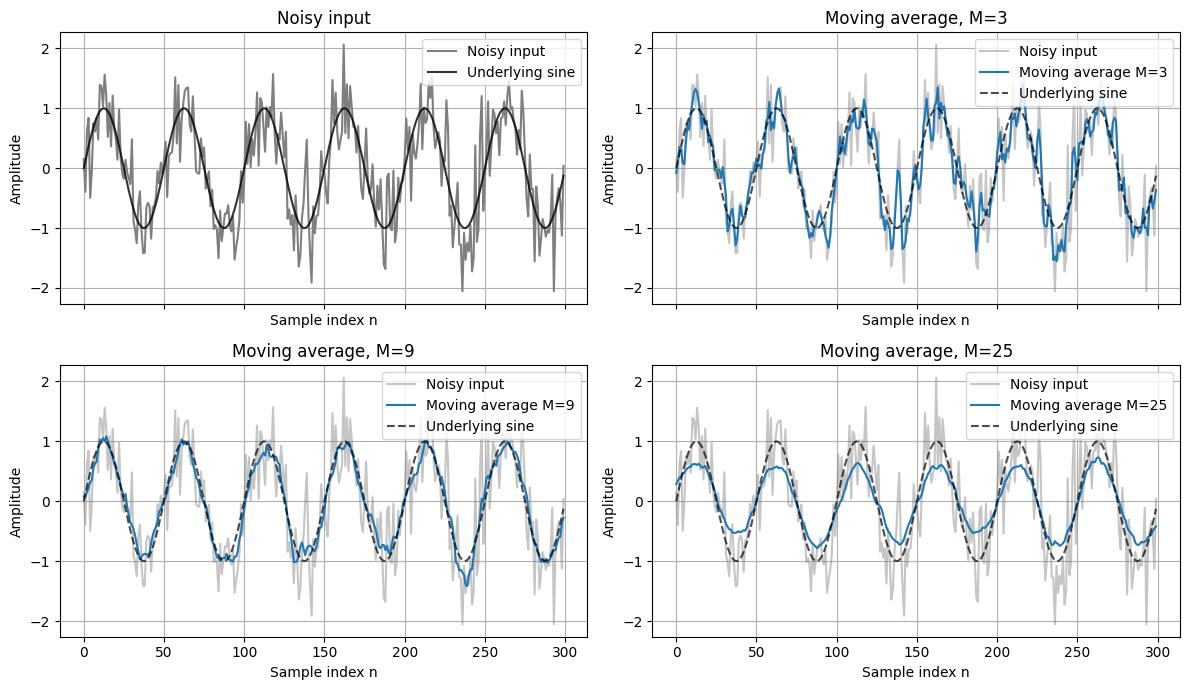

In [9]:
rng = np.random.default_rng(42)
n = np.arange(300)
clean = np.sin(2 * np.pi * n / 50)
noise = rng.standard_normal(300)
x_noisy = clean + 0.5 * noise

fig, axes = plt.subplots(2, 2, figsize=(12, 7), sharex=True)
axes = axes.ravel()
axes[0].plot(n, x_noisy, color="tab:gray", label="Noisy input")
axes[0].plot(n, clean, color="black", alpha=0.8, label="Underlying sine")
axes[0].set_title("Noisy input")
axes[0].legend()

for ax, M in zip(axes[1:], [3, 9, 25]):
    h = np.ones(M) / M
    smoothed = np.convolve(x_noisy, h, mode="same")
    ax.plot(n, x_noisy, color="tab:gray", alpha=0.45, label="Noisy input")
    ax.plot(n, smoothed, label=f"Moving average M={M}")
    ax.plot(n, clean, "k--", alpha=0.7, label="Underlying sine")
    ax.set_title(f"Moving average, M={M}")
    ax.legend()

for ax in axes:
    ax.set_xlabel("Sample index n")
    ax.set_ylabel("Amplitude")
plt.tight_layout()
plt.show()


**Observation.** Increasing M generally reduces more of the white noise. A longer averaging window also changes the signal more: it attenuates faster variations and can reduce the amplitude of the underlying sine. Use the plots above to refine this description for the displayed result.


## Task 3.3 Testing linearity and time-invariance numerically


In [10]:
rng = np.random.default_rng(0)
x1 = rng.standard_normal(50)
x2 = rng.standard_normal(50)
a, b = 2.0, -3.0

systems = {
    "x^2": lambda x: x ** 2,
    "n*x[n]": lambda x: np.arange(len(x)) * x,
    "moving average": lambda x: np.convolve(x, np.ones(3) / 3)[:len(x)],
}

for name, T in systems.items():
    linear = np.allclose(T(a * x1 + b * x2), a * T(x1) + b * T(x2))
    x_delayed = np.concatenate([np.zeros(5), x1])[:50]
    y_delayed = np.concatenate([np.zeros(5), T(x1)])[:50]
    time_invariant = np.allclose(T(x_delayed), y_delayed)
    print(f"{name:16s} linear={linear}  time-invariant={time_invariant}")


x^2              linear=False  time-invariant=True
n*x[n]           linear=True  time-invariant=False
moving average   linear=True  time-invariant=True


**Interpretation.** The expected results are: x² is nonlinear but time-invariant; n x[n] is linear but time-varying; and the fixed moving-average filter is linear and time-invariant (LTI). These results follow from the definitions and can be predicted before running the numerical test.


## Task 3.4  Finding a hidden delay with cross-correlation

The same seeded noise sequence is scaled at each noise level so the comparison is repeatable. The true delay is 37 samples at fs = 1000 Hz.


noise std=0.5: delay=37 samples, distance=12.691 m, reliable for this seeded example
noise std=1: delay=37 samples, distance=12.691 m, reliable for this seeded example
noise std=2: delay=37 samples, distance=12.691 m, reliable for this seeded example
noise std=4: delay=87 samples, distance=29.841 m, incorrect peak


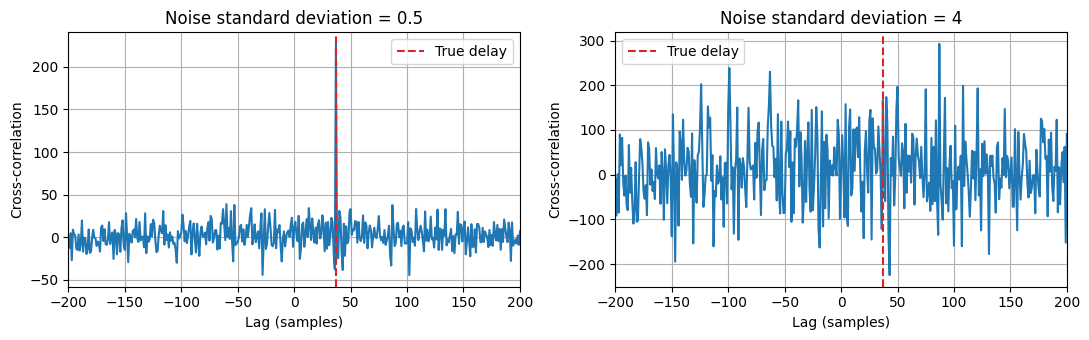

For the fixed seed, the estimate first fails at noise standard deviation 4.
A one-way sound path at 343 m/s travels 343 × 0.037 = 12.691 m in 37 ms.


In [11]:
rng = np.random.default_rng(1)
fs = 1000
x = rng.standard_normal(500)
true_delay = 37
delayed_signal = np.concatenate([np.zeros(true_delay), 0.6 * x])[:500]
unit_noise = rng.standard_normal(500)

noise_levels = [0.5, 1, 2, 4]
delay_results = {}
for noise_std in noise_levels:
    y = delayed_signal + noise_std * unit_noise
    r = signal.correlate(y, x, mode="full")
    lags = signal.correlation_lags(len(y), len(x), mode="full")
    estimated_delay = int(lags[np.argmax(r)])
    delay_results[noise_std] = estimated_delay
    distance = estimated_delay / fs * 343
    reliability = "reliable for this seeded example" if estimated_delay == true_delay else "incorrect peak"
    print(f"noise std={noise_std:g}: delay={estimated_delay} samples, "
          f"distance={distance:.3f} m, {reliability}")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
for ax, noise_std in zip(axes, [0.5, 4]):
    y = delayed_signal + noise_std * unit_noise
    r = signal.correlate(y, x, mode="full")
    lags = signal.correlation_lags(len(y), len(x), mode="full")
    ax.plot(lags, r)
    ax.axvline(true_delay, color="tab:red", linestyle="--", label="True delay")
    ax.set_xlim(-200, 200)
    ax.set_title(f"Noise standard deviation = {noise_std:g}")
    ax.set_xlabel("Lag (samples)")
    ax.set_ylabel("Cross-correlation")
    ax.legend()
plt.tight_layout()
plt.show()

print("For the fixed seed, the estimate first fails at noise standard deviation 4.")
print("A one-way sound path at 343 m/s travels 343 × 0.037 = 12.691 m in 37 ms.")


## Task 3.5  Difference equation

Use the coefficients corresponding to y[n] − 0.75y[n−1] + 0.125y[n−2] = x[n] + x[n−1].


n | direct recursion | lfilter | closed form
0 |       1.00000000 | 1.00000000 |  1.00000000
1 |       1.75000000 | 1.75000000 |  1.75000000
2 |       1.18750000 | 1.18750000 |  1.18750000
3 |       0.67187500 | 0.67187500 |  0.67187500
4 |       0.35546875 | 0.35546875 |  0.35546875
5 |       0.18261719 | 0.18261719 |  0.18261719
6 |       0.09252930 | 0.09252930 |  0.09252930
7 |       0.04656982 | 0.04656982 |  0.04656982
8 |       0.02336121 | 0.02336121 |  0.02336121
9 |       0.01169968 | 0.01169968 |  0.01169968


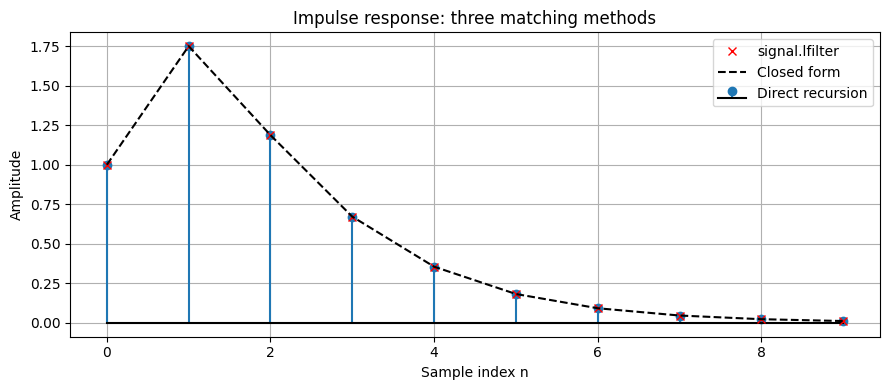

Step response at n=99: 5.33333333
DC gain H(1) = sum(b)/sum(a): 5.33333333
Poles: [0.5  0.25]


In [12]:
b = np.array([1.0, 1.0])
a = np.array([1.0, -0.75, 0.125])
n = np.arange(10)
impulse = np.zeros(10)
impulse[0] = 1.0

h_direct = np.zeros(10)
for k in range(10):
    x_now = impulse[k]
    x_previous = impulse[k - 1] if k >= 1 else 0.0
    y_previous = h_direct[k - 1] if k >= 1 else 0.0
    y_two_back = h_direct[k - 2] if k >= 2 else 0.0
    h_direct[k] = x_now + x_previous + 0.75 * y_previous - 0.125 * y_two_back

h_lfilter = signal.lfilter(b, a, impulse)
h_closed = 6 * (0.5 ** n) - 5 * (0.25 ** n)

print("n | direct recursion | lfilter | closed form")
for k in range(10):
    print(f"{k:1d} | {h_direct[k]:16.8f} | {h_lfilter[k]:7.8f} | {h_closed[k]:11.8f}")

plt.figure(figsize=(9, 4))
plt.stem(n, h_direct, linefmt="C0-", markerfmt="C0o", basefmt="k-", label="Direct recursion")
plt.plot(n, h_lfilter, "rx", label="signal.lfilter")
plt.plot(n, h_closed, "k--", label="Closed form")
plt.title("Impulse response: three matching methods")
plt.xlabel("Sample index n")
plt.ylabel("Amplitude")
plt.legend()
plt.tight_layout()
plt.show()

unit_step = np.ones(100)
step_response = signal.lfilter(b, a, unit_step)
H_at_1 = np.sum(b) / np.sum(a)
print(f"Step response at n=99: {step_response[-1]:.8f}")
print(f"DC gain H(1) = sum(b)/sum(a): {H_at_1:.8f}")
print("Poles:", np.roots(a))


## Analysis questions

### 1. Why is np.convolve faster? How many multiplications?

The direct function executes nested loops in the Python interpreter. NumPy performs its convolution loop in optimized compiled code, which avoids much of that per-iteration interpreter overhead. For finite sequences of lengths L and M, every pair of samples contributes once, so there are L × M pairwise multiplications (4,000,000 when L = M = 2000).

### 2. Which systems are LTI?

The moving average is LTI because it is convolution with a fixed impulse response. The system x² is time-invariant but nonlinear because squaring does not satisfy superposition. The system n x[n] is linear but time-varying because its multiplier depends on n.

### 3. Two engineering applications of cross-correlation

Examples include estimating the position of a water-pipe leak from time differences between acoustic sensors, and matching GPS/radar received signals to a known reference to estimate propagation delay. Add any local example discussed in your class.

### 4. Is the Task 3.5 system FIR or IIR? Is it stable?

It is IIR because the denominator has feedback terms and the impulse response continues beyond a finite number of samples. It is stable: its poles are 0.5 and 0.25, both inside the unit circle, and the given impulse response decays as a sum of powers with magnitudes below one. Its absolute sum is finite.


## Conclusion and deliverables
This laboratory demonstrated how convolution, correlation, and difference equations are used in digital signal processing. The direct convolution function agreed with NumPy’s result, while the moving-average filter reduced noise more as its window length increased, at the cost of greater distortion to the original sine wave. The system tests showed that x² is nonlinear but time-invariant, n·x[n] is linear but time-varying, and the moving-average filter is LTI. Cross-correlation recovered the 37-sample delay at lower noise levels; with the fixed random seed, the estimate became unreliable at a noise standard deviation of 4. Finally, the direct recursion, signal.lfilter, and closed-form impulse responses agreed. The system is a stable IIR filter, and its steady-state step response agreed with the DC gain H(1) ≈ 5.33.

## AI-use statement

AI tools used: OpenAI ChatGPT/Codex.  
Used for: preparing starter code and explanations, solving the pre-lab convolution and time-invariance questions, and organizing this notebook.  
I confirm that I understand and can explain all submitted code.
